# Comparación de datos: réplicas LAB019-021 vs originales LAB004/006/009

**Alcance:** comparación *pura de datos de laboratorio* entre cada réplica (septiembre 2026) y su
original de abril 2026. **Sin modelo, sin theta, sin capa CO2** — ese análisis vive en notebooks posteriores.

| Par | Original (abril) | Réplica (sept) | Protocolo |
|---|---|---|---|
| 1 | LAB004 | LAB019 | A: 18°C → 21°C@99h → 16°C@171h; pulso 2 original t=51h |
| 2 | LAB006 | LAB020 | C arranque frío: 16°C → 18°C@123h → 21°C@219h; pulso 2 original t=75h |
| 3 | LAB009 | LAB021 | A: 18°C → 21°C@96h → 16°C@168h; pulso 2 original t=48h |

**Fuentes:** workbook homologado `mosto_natural_xthiol.xlsx` (hojas LAB004/006/009) para los
originales; para las réplicas: exports Y15 (EXPAuto/ONLINE), `Mediciones-Offline-LAB019-021.xlsx`
(densidad/Brix/etanol/horas de muestreo) y `Oculyze_report_LAB*.csv` (concentración, con resta de la fila CERO).

**Decisiones de diseño:**
- Dos alineaciones: por **reloj** (t desde el t0 de cada lote) y por **estado** (azúcar consumida), para separar diferencias de *velocidad* de diferencias de *forma*.
- La temperatura de la columna del Anton Paar del Excel offline **no se usa** (medición de T de muestra no confiable); el log de temperatura del biorreactor se incorporará en notebooks posteriores.
- La columna `Viability` del workbook homologado es un duplicado de la concentración Oculyze (corrupta): no se grafica; la viabilidad de las réplicas sí.
- Puntos con flag de QA se **marcan en rojo**, no se eliminan silenciosamente; la lista completa se exporta a `qa_flags.csv`.
- La columna `Etanol` del Excel offline (Alcolyzer, % v/v, sólo en m1/m4/m7/m10/m11/m12) se compara contra `ETANOL`
  del workbook, que está en la misma unidad (el rótulo antiguo "g/L" era un error).
- Las alícuotas de Alcolyzer de m12 se diluyeron, distinto por lote: LAB020 con 27.5 mL de vino + 10 mL de agua
  y LAB021 con 32.5 mL de vino + 5 mL de agua (ambas a 37.5 mL); su etanol se corrige ×37.5/27.5 y ×37.5/32.5
  respectivamente. Brix y densidad de esas filas se midieron ANTES de diluir y no se corrigen.
- Nitrógeno en mg N/L: YAN = PAN + 0.823·NH3 (validado contra el canal YAN del propio Y15 en PI).

Este `.ipynb` es el SOURCE limpio; el archivo `.executed.ipynb` contiene las salidas del Run All.


In [1]:
from pathlib import Path
import csv
import re
import sys
from datetime import datetime, time as dtime

import matplotlib.pyplot as plt
from IPython import get_ipython
_ip = get_ipython()
if _ip is not None:
    _ip.run_line_magic("matplotlib", "inline")
import numpy as np
import openpyxl
import pandas as pd
from IPython.display import display

candidates = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
ROOT = next(path for path in candidates if (path / "fermentation_model").exists())
FM = ROOT / "fermentation_model"

WORKBOOK_PATH = FM / "data" / "Laboratorio 2026" / "Vendimia_2026" / "mosto_natural_xthiol.xlsx"
REPLICA_DIR = FM / "data" / "mem2026" / "LAB019-021"
OFFLINE_PATH = REPLICA_DIR / "Mediciones-Offline-LAB019-021.xlsx"
Y15_PATHS = sorted(REPLICA_DIR.glob("EXPAuto*.txt")) + sorted(REPLICA_DIR.glob("ONLINE*.txt"))
OCULYZE_PATHS = {lab: REPLICA_DIR / f"Oculyze_report_{lab}.csv" for lab in ("LAB019", "LAB020", "LAB021")}

RESULTS_DIR = FM / "laboratory_2026" / "results" / "lab019_021_replica_vs_originals_data_comparison"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

required = [WORKBOOK_PATH, OFFLINE_PATH, *Y15_PATHS, *OCULYZE_PATHS.values()]
assert all(path.exists() for path in required), [str(path) for path in required if not path.exists()]
assert Y15_PATHS, "No se encontraron exportaciones Y15"

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 180, "font.size": 9.5, "axes.titlesize": 10.5})

COLOR_ORIG = "#4c72b0"
COLOR_REPL = "#dd8452"
COLOR_FLAG = "#d62728"

if str(FM) not in sys.path:
    sys.path.insert(0, str(FM))
from laboratory_2026.nut_sample_audit import load_nut_samples
from IPython.display import Image
import io
NUT_SAMPLE_TIMES = {}  # lab: fecha-hora de extracción confirmada; vacío = intervalo provisional
def display_inline_figure(fig):
    buffer = io.BytesIO()
    fig.savefig(buffer, format='png', dpi=110, bbox_inches='tight')
    plt.close(fig)
    display(Image(data=buffer.getvalue()))


## Constantes de campaña (t0, eventos, umbrales)

- t0 de cada lote se lee de sus propios datos (fila t=0 del workbook; 21/09 17:00 = aplicación de levadura en las réplicas (confirmado por laboratorio; el pulso 1 se dosificó al mosto antes del inóculo, por lo que la muestra 01 es pre-inoculación)).
- Pulsos 2: originales con las horas documentadas (planificación de la réplica / `effective_nutrient_pulses`); réplicas con fecha-hora real desde la hoja `Nutricion` del Excel offline.
- Los cambios de setpoint son idénticos por diseño en cada par: se dibujan una sola vez (líneas punteadas).

In [2]:
PAIRS = [
    ("LAB004", "LAB019", "Protocolo A (18->21@99h->16@171h)"),
    ("LAB006", "LAB020", "Protocolo C arranque frío (16->18@123h->21@219h)"),
    ("LAB009", "LAB021", "Protocolo A (18->21@96h->16@168h)"),
]
SP_EVENTS = {  # (t_h, setpoint C) — idénticos en original y réplica por diseño
    "LAB004": [(99, 21), (171, 16)],
    "LAB006": [(123, 18), (219, 21)],
    "LAB009": [(96, 21), (168, 16)],
}
PULSE_ORIG_H = {"LAB004": 51.0, "LAB006": 75.0, "LAB009": 48.0}
PULSE_REPL_DT = {  # hoja Nutricion del Excel offline, ejecutado real (disparo por densidad ~1040)
    "LAB019": datetime(2026, 9, 24, 9, 20),
    "LAB020": datetime(2026, 9, 24, 16, 40),
    "LAB021": datetime(2026, 9, 23, 16, 30),
}
T0_REPL = {lab: datetime(2026, 9, 21, 17, 0) for lab in PULSE_REPL_DT}  # aplicacion de levadura (confirmado laboratorio); no 16:00 del plan

GF_THRESHOLDS = [100.0, 90.0, 40.0]
DENSITY_THRESHOLD = 1040.0
NH3_THRESHOLD = 5.0
BRIX_VALID_MAX = 17.5  # Brix '22.5/22.6' en filas tardías del workbook = error de ingreso

## Carga de originales (workbook homologado)

In [3]:
ORIG_COLS = {  # índice de columna en la hoja (0-based)
    "fecha": 1, "t": 2, "densidad": 4, "peso_seco": 6, "glucosa": 7, "fructosa": 8,
    "pan": 9, "nh3": 10, "yan": 11, "glicerol": 12, "piruvico": 13, "acetaldehido": 15,
    "etanol": 16, "brix": 36, "ocu_conc": 39,
}

def num(value):
    try:
        out = float(value)
        return out if np.isfinite(out) else np.nan
    except (TypeError, ValueError):
        return np.nan

ORIG, T0_ORIG = {}, {}
wb = openpyxl.load_workbook(WORKBOOK_PATH, read_only=True, data_only=True)
for lab in ("LAB004", "LAB006", "LAB009"):
    rows = []
    for r in wb[lab].iter_rows(min_row=2, values_only=True):
        t = num(r[ORIG_COLS["t"]])
        gf = num(r[ORIG_COLS["glucosa"]]) + num(r[ORIG_COLS["fructosa"]])
        dens = num(r[ORIG_COLS["densidad"]])
        if not np.isfinite(t) or (not np.isfinite(gf) and not np.isfinite(dens)):
            continue  # filas marcadoras vacías (t=68/99/41)
        stamp = pd.to_datetime(r[ORIG_COLS["fecha"]])
        if abs(t) < 1e-9:
            T0_ORIG[lab] = stamp.to_pydatetime()
        brix = num(r[ORIG_COLS["brix"]])
        rows.append({
            "t_h": t, "GF": gf, "YAN": num(r[ORIG_COLS["yan"]]), "NH3": num(r[ORIG_COLS["nh3"]]),
            "Gly": num(r[ORIG_COLS["glicerol"]]), "density": dens, "Brix": brix,
            "Brix_valid": brix if (np.isfinite(brix) and brix <= BRIX_VALID_MAX) else np.nan,
            "X_ocu": num(r[ORIG_COLS["ocu_conc"]]), "peso_seco": num(r[ORIG_COLS["peso_seco"]]),
            "etanol": num(r[ORIG_COLS["etanol"]]), "piruvico": num(r[ORIG_COLS["piruvico"]]),
            "acetaldehido": num(r[ORIG_COLS["acetaldehido"]]),
        })
    ORIG[lab] = pd.DataFrame(rows).set_index("t_h").sort_index()
wb.close()
assert set(T0_ORIG) == {"LAB004", "LAB006", "LAB009"}
for lab, df in ORIG.items():
    print(lab, "t0 =", T0_ORIG[lab], "| n:", {c: int(df[c].notna().sum()) for c in ("GF", "YAN", "density", "Brix_valid", "X_ocu")})

LAB004 t0 = 2026-04-06 13:00:00 | n: {'GF': 13, 'YAN': 13, 'density': 13, 'Brix_valid': 12, 'X_ocu': 12}
LAB006 t0 = 2026-04-06 13:00:00 | n: {'GF': 15, 'YAN': 15, 'density': 15, 'Brix_valid': 14, 'X_ocu': 14}
LAB009 t0 = 2026-04-17 16:00:00 | n: {'GF': 12, 'YAN': 12, 'density': 11, 'Brix_valid': 11, 'X_ocu': 12}


## Carga de réplicas (Excel offline + Y15 + Oculyze)

Fallbacks documentados:
- Filas de la muestra 11 del Excel aún sin metadatos: se asignan en orden F1/F2/F3 con fecha-hora 25/09 08:30 (hora de visita, corroborada por la descripción de Oculyze). **Flag.**
- Tiempos de observación = hora de *muestreo* del Excel (no la hora de medición del Y15); la muestra 1 de Oculyze usa su propio timestamp (17:21, muestra extra post-inoculación). **Flag.**
- La densidad "1070" de Oculyze muestra 1 (tres reactores, T=0) es un placeholder de la app: no se usa; la densidad maestra es la del Excel.
Las muestras offline se leen por sus metadatos reales. Las exportaciones Y15 presentes se incorporan automáticamente; las muestras sin Y15 conservan Brix/densidad y quedan marcadas en QA.

Para m12 se conservan los canales de azúcar crudos: los resultados negativos no se grafican como concentraciones. Cuando `GLU-FRU-320` es negativo, se usa `GLUCOSE-FRUCTOSE` si entrega un valor no negativo.

### Muestras de nutrición NUT

Se incorporan `LAB019-NUT`, `LAB020-NUT` y `LAB021-NUT`, que estaban en las
exportaciones Y15 pero quedaban fuera al seleccionar sólo muestras numeradas.
Contienen PAN, amonio y YAN; los otros canales permanecen ausentes.
Se conserva YAN informado y YAN calculado con PAN + 0,823·max(NH3,0), sin duplicarlos
como mediciones independientes. Los registros YAN repetidos idénticos se deduplican.

La hora de extracción no está en `MedicionesOffline`. Provisionalmente, suponiendo
que NUT se tomó después de la adición, se representa en el punto medio del intervalo
entre el pulso 2 registrado y el primer análisis de N de esa muestra. El intervalo se
dibuja horizontalmente y **no representa una precisión estadística**. La hora de
análisis se conserva separada; no se presenta como una hora de muestreo conocida.
`NUT_SAMPLE_TIMES` permite introducir horas de extracción confirmadas.


In [4]:
MESES = {m: i + 1 for i, m in enumerate(
    ["enero", "febrero", "marzo", "abril", "mayo", "junio", "julio", "agosto",
     "septiembre", "octubre", "noviembre", "diciembre"])}

def parse_oculyze_stamp(date_s, time_s):
    d = re.match(r"(\d{1,2}) de (\w+) de (\d{4})", date_s.strip())
    t = re.match(r"(\d{1,2}):(\d{2}):(\d{2}) (a|p)\. m\.", time_s.strip())
    assert d and t, (date_s, time_s)
    hora = int(t.group(1)) % 12 + (12 if t.group(4) == "p" else 0)
    return datetime(int(d.group(3)), MESES[d.group(2)], int(d.group(1)), hora, int(t.group(2)), int(t.group(3)))

def load_offline():
    wb = openpyxl.load_workbook(OFFLINE_PATH, read_only=True, data_only=True)
    rows = []
    for excel_row, r in enumerate(wb["MedicionesOffline"].iter_rows(min_row=2, values_only=True), start=2):
        fecha, hora, lab, brix, dens = r[0], r[1], r[2], r[5], r[6]
        if lab is None and brix is None and dens is None:
            continue
        if lab not in ("LAB019", "LAB020", "LAB021") or fecha is None or hora is None or r[4] is None:
            raise ValueError(f"MedicionesOffline fila {excel_row}: metadatos incompletos")
        hh = hora.time() if isinstance(hora, datetime) else hora
        rows.append({"lab": lab, "muestra": str(r[4]).strip(),
                     "stamp": datetime.combine(fecha.date() if hasattr(fecha, "date") else fecha, hh),
                     "Brix": num(brix), "density": num(dens), "Etanol_pct": num(r[10])})
    wb.close()
    result = pd.DataFrame(rows)
    assert not result.duplicated(["lab", "muestra"]).any(), "muestras offline duplicadas"
    return result

def load_y15():
    frames = []
    for path in Y15_PATHS:
        for line in open(path, encoding="utf-8-sig", errors="replace"):
            p = line.rstrip("\n").split("\t")
            if len(p) < 6:
                continue
            val = float(p[3].replace(",", ".")) if re.fullmatch(r"-?\d+(,\d+)?", p[3].strip()) else np.nan
            frames.append({"sample": p[0], "ana": p[1], "val": val})
    df = pd.DataFrame(frames).drop_duplicates(["sample", "ana"], keep="first")
    return df.pivot(index="sample", columns="ana", values="val")

def load_oculyze():
    out = {}
    for lab, path in OCULYZE_PATHS.items():
        cero, rows = np.nan, []
        with open(path, encoding="utf-8-sig", newline="") as fh:
            for r in csv.DictReader(fh):
                if r["Name"].strip() == "CERO":
                    cero = num(r["Concentration"])
                    continue
                m = re.fullmatch(r"(LAB\d+)-(\d+)", r["Name"].strip())
                if not m:
                    continue
                rows.append({"lab": m.group(1), "n": int(m.group(2)),
                             "stamp_ocu": parse_oculyze_stamp(r["Date"], r["Time"]),
                             "X_ocu": num(r["Concentration"]) - cero,  # 'VALOR BASE RESTAR'
                             "viab": num(r["Viability"]), "budding": num(r["Budding Index"])})
        out[lab] = pd.DataFrame(rows)
    return out

OFFLINE = load_offline()
# Dilución Alcolyzer m12, distinta por lote (cuaderno de laboratorio): LAB020 27.5 mL de vino + 10 mL de agua;
# LAB021 32.5 mL de vino + 5 mL de agua (ambas a 37.5 mL). Sólo corrige etanol (medido en la mezcla);
# Brix y densidad se midieron antes de diluir.
DILUTION_FACTORS_M12 = {"LAB020": 37.5 / 27.5, "LAB021": 37.5 / 32.5}
for _lab_m12, _factor in DILUTION_FACTORS_M12.items():
    _sel = OFFLINE["lab"].eq(_lab_m12) & OFFLINE["muestra"].eq("12")
    OFFLINE.loc[_sel, "Etanol_pct"] = OFFLINE.loc[_sel, "Etanol_pct"] * _factor
assert np.isclose(OFFLINE.loc[(OFFLINE["lab"] == "LAB020") & (OFFLINE["muestra"] == "12"), "Etanol_pct"].iloc[0], 7.33 * 15 / 11)
assert np.isclose(OFFLINE.loc[(OFFLINE["lab"] == "LAB021") & (OFFLINE["muestra"] == "12"), "Etanol_pct"].iloc[0], 8.66 * 15 / 13)
Y15 = load_y15()
OCU = load_oculyze()
print("offline:", OFFLINE.shape, "| Y15 pivot:", Y15.shape, "| oculyze:", {k: len(v) for k, v in OCU.items()})

NUT_SAMPLES = load_nut_samples(REPLICA_DIR, T0_REPL, NUT_SAMPLE_TIMES)
NUT_SAMPLES.to_csv(RESULTS_DIR / 'nut_sample_audit.csv', index=False)
display(NUT_SAMPLES[['lab','PAN_mg_l','NH3_raw_mg_l','YAN_reported_mg_l','YAN_mg_l',
                     'pulse_timestamp','analysis_PAN','analysis_YAN','sample_timestamp',
                     'time_lower_h','plot_t_h','time_upper_h','time_provisional']])


offline: (39, 6) | Y15 pivot: (42, 15) | oculyze: {'LAB019': 11, 'LAB020': 11, 'LAB021': 11}


,lab,PAN_mg_l,NH3_raw_mg_l,YAN_reported_mg_l,YAN_mg_l,pulse_timestamp,analysis_PAN,analysis_YAN,sample_timestamp,time_lower_h,plot_t_h,time_upper_h,time_provisional
0,LAB019,52.0,58.0,100.0,99.734,2026-09-24 09:20:00,2026-09-24 09:41:52,2026-09-24 09:43:04,NaT,64.333333,64.515556,64.697778,True
1,LAB020,55.0,65.0,108.0,108.495,2026-09-24 16:40:00,2026-09-24 17:11:03,2026-09-24 17:12:39,NaT,71.666667,71.925417,72.184167,True
2,LAB021,37.0,50.0,78.0,78.150,2026-09-23 16:30:00,2026-09-23 16:51:00,2026-09-23 16:52:36,NaT,47.500000,47.675000,47.850000,True


In [5]:
def replica_frame(lab):
    base = OFFLINE[OFFLINE["lab"] == lab].copy()
    base["t_h"] = [(s - T0_REPL[lab]).total_seconds() / 3600.0 for s in base["stamp"]]
    numbered = sorted((item for item in base["muestra"] if str(item).isdigit()), key=int)
    y15 = Y15.reindex([f"{lab}-PREH2O2"] + [f"{lab}-{i}" for i in numbered])
    y15.index = ["PI"] + numbered
    df = base.set_index("muestra").join(y15)
    nh3_raw = df.get("AMMONIA")
    yan = df.get("PAN") + 0.823 * nh3_raw.clip(lower=0.0)  # mismo censurado de NH3 que el holdout
    gf_320 = df.get("GLU-FRU-320")
    gf_low = df.get("GLUCOSE-FRUCTOSE")
    gf_320_valid = gf_320.where(gf_320 >= 0.0)
    gf_low_valid = gf_low.where(gf_low >= 0.0)
    gf = gf_320_valid.combine_first(gf_low_valid)
    gf_source = pd.Series("", index=df.index, dtype=object)
    gf_source.loc[gf_320_valid.notna()] = "GLU-FRU-320"
    gf_source.loc[gf_320_valid.isna() & gf_low_valid.notna()] = "GLUCOSE-FRUCTOSE"
    g_320 = df.get("GLUCOSE-320")
    g_low = df.get("GLUCOSE")
    glucose = g_320.where(g_320 >= 0.0).combine_first(g_low.where(g_low >= 0.0))
    out = pd.DataFrame({
        "GF": gf, "GF_source": gf_source, "GF_320_raw": gf_320, "GF_low_raw": gf_low,
        "G": glucose, "YAN_mgN": yan,
        "NH3": nh3_raw, "Gly": df.get("GLYCEROL"), "density": df["density"], "Brix": df["Brix"],
        "acetic": df.get("ACETIC ACID"), "piruvico": df.get("PYRUVIC ACID"),
        "acetaldehido": df.get("ACETALDEHID-1000"), "etanol": df["Etanol_pct"],
    })
    out["t_h"] = df["t_h"]
    out["PAN_mg_l"] = df["PAN"]
    out["is_NUT"] = False
    out["time_provisional"] = False
    out["time_lower_h"] = out["t_h"]
    out["time_upper_h"] = out["t_h"]
    out["sample_timestamp"] = df["stamp"]
    nut = NUT_SAMPLES[NUT_SAMPLES.lab.eq(lab)].iloc[0]
    extra = {column: np.nan for column in out.columns}
    extra.update(YAN_mgN=nut.YAN_mg_l, PAN_mg_l=nut.PAN_mg_l, NH3=nut.NH3_raw_mg_l,
                 t_h=nut.plot_t_h, is_NUT=True, time_provisional=bool(nut.time_provisional),
                 time_lower_h=nut.time_lower_h, time_upper_h=nut.time_upper_h,
                 sample_timestamp=nut.sample_timestamp, GF_source='')
    out = pd.concat([out, pd.DataFrame([extra], index=pd.Index(['NUT'], name=out.index.name))]).sort_values('t_h')
    ocu = OCU[lab].copy()
    ocu["t_h"] = [(s - T0_REPL[lab]).total_seconds() / 3600.0 for s in ocu["stamp_ocu"]]
    # hora de observación: muestreo del Excel para m2+; m1 usa su propio stamp (17:21, extra post-inoculación)
    excel_t = dict(zip(base["muestra"], base["t_h"]))
    ocu["t_h"] = [ocu_t if n == 1 else excel_t.get(str(n), ocu_t)
                  for n, ocu_t in zip(ocu["n"], ocu["t_h"])]
    return out, ocu.set_index("t_h").sort_index()[["X_ocu", "viab", "budding"]]

REPL, REPL_X = {}, {}
for lab in ("LAB019", "LAB020", "LAB021"):
    REPL[lab], REPL_X[lab] = replica_frame(lab)
    print(lab, "| n GF:", int(REPL[lab]["GF"].notna().sum()),
          "| t de", round(REPL[lab]["t_h"].min(), 1), "a", round(REPL[lab]["t_h"].max(), 1),
          "h | n X:", int(REPL_X[lab]["X_ocu"].notna().sum()),
          "| muestras sin Y15:", [i for i in REPL[lab].index if i != "PI" and REPL[lab].loc[i, ["GF", "YAN_mgN", "Gly"]].isna().all()])

for lab in REPL:
    assert 'NUT' in REPL[lab].index
    assert REPL[lab].loc['NUT', ['GF','Gly','density','Brix','etanol']].isna().all()
pd.concat([frame.rename_axis('sample').reset_index().assign(lab=lab)
           for lab,frame in REPL.items()], ignore_index=True).to_csv(
               RESULTS_DIR/'replica_measurements_with_NUT.csv', index=False)

def draw_nut(ax, lab, panel, state_axis=False):
    if lab not in REPL or panel not in ('YAN','NH3'):
        return
    row = REPL[lab].loc['NUT']
    y = row['YAN_mgN'] if panel == 'YAN' else row['NH3']
    lo, x, hi = float(row.time_lower_h), float(row.t_h), float(row.time_upper_h)
    label = 'NUT · tiempo provisional' if row.time_provisional else 'NUT · hora confirmada'
    if state_axis:
        measured = REPL[lab].dropna(subset=['GF']).sort_values('t_h')
        c0 = float(measured.GF.iloc[0])
        c = c0-np.interp([lo,x,hi],measured.t_h,measured.GF)
        x = float(c[1]); lo, hi = float(min(c)), float(max(c))
        label = 'NUT · azúcar interpolada'
    ax.errorbar([x],[y],xerr=[[max(x-lo,0.)],[max(hi-x,0.)]],fmt='D',
                color='#8e24aa',ms=6,capsize=3,lw=1.5,zorder=7,label=label)


LAB019 | n GF: 11 | t de -4.5 a 166.0 h | n X: 11 | muestras sin Y15: []
LAB020 | n GF: 12 | t de -4.5 a 166.0 h | n X: 11 | muestras sin Y15: []
LAB021 | n GF: 10 | t de -4.5 a 166.0 h | n X: 11 | muestras sin Y15: []


## Flags de QA (se marcan, no se borran)

In [6]:
PULSE_REPL_H = {lab: (dt - T0_REPL[lab]).total_seconds() / 3600.0 for lab, dt in PULSE_REPL_DT.items()}

QA_FLAGS = [
    ("LAB004", "GF", "t=0", "GF0=145.9 con densidad 1067.7: 12 g/L bajo respecto a LAB019 a igual densidad; inconsistente", "marcado"),
    ("LAB004", "Brix", "t=146", "Brix 22.6 en vino casi seco = error de ingreso (regla Brix<=17.5)", "excluido por regla"),
    ("LAB006", "Brix", "t=146", "Brix 22.5 ídem", "excluido por regla"),
    ("LAB004/006/009", "Viability", "todo", "columna duplicada de la concentración Oculyze en el workbook, no es viabilidad", "no graficada"),
    ("LAB009", "X_ocu", "t=160", "concentración/viabilidad con crash final (6.8/4.6%) atípico", "marcado"),
    ("LAB004/006", "acetic", "todo", "canal 'Y15 Acetico' vacío en el workbook (sólo LAB009 tiene acético)", "panel secundario sin original"),
    ("LAB019", "GF", "m4", "GF 151.2 g/L por sobre el valor de m3 (no monótono); outlier Y15", "marcado"),
    ("LAB020", "G", "m4", "glucosa -7.28 g/L inválida", "canal G sin punto"),
    ("LAB019/020/021", "G", "m5-m7 (23-09)", "canal GLUCOSE-320 'Out' todo el miércoles 23/09", "sin split glu/fru ese día"),
    ("LAB021", "GF", "m8/m11", "GF faltante (m8) y 'Out High' (m11, glucosa 1.10)", "sin punto"),
    ("LAB019", "X_ocu", "m1", "28.65 medida 17:21 = 21 min post-inoculación (17:00): inóculo fresco sin mezclar del todo; plausible, no artefacto", "marcado"),
    ("LAB019/LAB021", "X_ocu", "m9", "concentración idéntica 72.12 en dos reactores: posible repetición en la app", "marcado"),
    ("LAB019/020/021", "density", "PI", "hora PI del Excel (12:30) pendiente de corrección a 15:10", "usada hora Excel"),
    ("LAB019/020/021", "T", "todo", "temperatura Anton Paar no confiable: excluida de este análisis", "canal excluido"),
    ("LAB019/020/021", "etanol", "m1", "pre-inoculación con ~1.5% v/v: señal basal del equipo, mismo patrón que los originales (ETANOL t=0 1.23-1.25)", "marcado"),
    ("LAB019/020/021", "etanol", "m1,m4,m7,m10,m11,m12", "Alcolyzer medido sólo en 6 de 12 muestras", "panel secundario con huecos"),
    ("LAB020", "etanol", "m12", "alícuota diluida 27.5->37.5 mL; corregida x15/11 (7.33 -> 10.00 % v/v)", "corregido"),
    ("LAB021", "etanol", "m12", "alícuota diluida 32.5->37.5 mL; corregida x15/13 (8.66 -> 9.99 % v/v), consistente con LAB019 (9.91, sin diluir)", "corregido"),
]
for lab in ("LAB019", "LAB020", "LAB021"):
    for sample in REPL[lab].index:
        if sample != "PI" and REPL[lab].loc[sample, ["GF", "YAN_mgN", "Gly"]].isna().all():
            QA_FLAGS.append((lab, "Y15", f"m{sample}", "no existe exportación Y15 para esta muestra", "solo Brix/densidad"))
for lab in ("LAB019", "LAB020", "LAB021"):
    if "12" not in REPL[lab].index:
        continue
    row = REPL[lab].loc["12"]
    if pd.notna(row["GF_320_raw"]) and row["GF_320_raw"] < 0:
        action = "rango bajo usado" if row["GF_source"] == "GLUCOSE-FRUCTOSE" else "sin punto GF"
        QA_FLAGS.append((lab, "GF", "m12", "GLU-FRU-320 negativo; rango bajo auditado", action))
    if pd.isna(row["G"]):
        QA_FLAGS.append((lab, "G", "m12", "glucosa de rango bajo negativa", "sin punto G"))
for nut in NUT_SAMPLES.itertuples():
    QA_FLAGS.append((nut.lab, 'NUT', 'NUT',
        'extracción desconocida: intervalo provisional pulso–primer análisis' if nut.time_provisional else 'hora de extracción confirmada',
        'incluida; canales PAN/NH3/YAN; sin inventar otros canales'))
flags_df = pd.DataFrame(QA_FLAGS, columns=["lote", "canal", "muestra", "problema", "acción"])
flags_df.to_csv(RESULTS_DIR / "qa_flags.csv", index=False, encoding="utf-8-sig")
display(flags_df)

# puntos que se marcan en rojo en las figuras: (lab, panel) -> [(t_h, valor)]
FLAG_MARKS = {}
def add_mark(lab, panel, t, v):
    if np.isfinite(t) and np.isfinite(v):
        FLAG_MARKS.setdefault((lab, panel), []).append((float(t), float(v)))

add_mark("LAB004", "GF", ORIG["LAB004"].index[0], ORIG["LAB004"]["GF"].iloc[0])
add_mark("LAB019", "GF", REPL["LAB019"].loc["4", "t_h"], REPL["LAB019"].loc["4", "GF"])
for lab in ("LAB019", "LAB021"):  # X: m1 (slug) y m9 (duplicado 72.12)
    xf = REPL_X[lab]
    for n_row, ocu in zip(OCU[lab]["n"], xf.itertuples()):
        if n_row in (1, 9):
            add_mark(lab, "X", ocu.Index, ocu.X_ocu)
lab009x = ORIG["LAB009"]
add_mark("LAB009", "X", lab009x.index[-1], lab009x["X_ocu"].iloc[-1])
# LAB021 m12 etanol corregido (9.99 % v/v) ya no es anómalo: sin marca

,lote,canal,muestra,problema,acción
0,LAB004,GF,t=0,GF0=145.9 con densidad 1067.7: 12 g/L bajo res...,marcado
1,LAB004,Brix,t=146,Brix 22.6 en vino casi seco = error de ingreso...,excluido por regla
2,LAB006,Brix,t=146,Brix 22.5 ídem,excluido por regla
3,LAB004/006/009,Viability,todo,columna duplicada de la concentración Oculyze ...,no graficada
4,LAB009,X_ocu,t=160,concentración/viabilidad con crash final (6.8/...,marcado
5,LAB004/006,acetic,todo,canal 'Y15 Acetico' vacío en el workbook (sólo...,panel secundario sin original
6,LAB019,GF,m4,GF 151.2 g/L por sobre el valor de m3 (no monó...,marcado
7,LAB020,G,m4,glucosa -7.28 g/L inválida,canal G sin punto
8,LAB019/020/021,G,m5-m7 (23-09),canal GLUCOSE-320 'Out' todo el miércoles 23/09,sin split glu/fru ese día
9,LAB021,GF,m8/m11,"GF faltante (m8) y 'Out High' (m11, glucosa 1.10)",sin punto


## Hitos por lote

Cruce de densidad 1040, tiempo a GF=100/90/40 y agotamiento de NH3 (primera vez ≤ 5 mg/L),
interpolados en cada serie. `NaN` = aún no alcanzado (campaña en curso).

In [7]:
def first_crossing(time, values, threshold, direction="below"):
    t = np.asarray(time, float); v = np.asarray(values, float)
    ok = np.isfinite(t) & np.isfinite(v)
    t, v = t[ok], v[ok]
    if len(v) < 2:
        return np.nan
    for i in range(len(v) - 1):
        v0, v1 = v[i], v[i + 1]
        hit = (v0 > threshold >= v1) if direction == "below" else (v0 < threshold <= v1)
        if hit:
            frac = 0.0 if v1 == v0 else (threshold - v0) / (v1 - v0)
            return t[i] + frac * (t[i + 1] - t[i])
    return np.nan

MILESTONE_DEFS = [
    ("t_cruce_dens1040_h", "dens 1040"), ("t_GF100_h", "GF 100"), ("t_GF90_h", "GF 90"),
    ("t_GF40_h", "GF 40"), ("t_NH3_agotado_h", "NH3 <= 5"),
]

def milestone_row(lab, is_replica):
    df = REPL[lab] if is_replica else ORIG[lab]
    t = df["t_h"] if is_replica else df.index
    return {"lote": lab,
            "t_cruce_dens1040_h": first_crossing(t, df["density"], DENSITY_THRESHOLD),
            "t_GF100_h": first_crossing(t, df["GF"], 100.0),
            "t_GF90_h": first_crossing(t, df["GF"], 90.0),
            "t_GF40_h": first_crossing(t, df["GF"], 40.0),
            "t_NH3_agotado_h": first_crossing(t, df["NH3"], NH3_THRESHOLD)}

rows = []
for orig, repl, _ in PAIRS:
    rows.append(milestone_row(orig, False))
    r = milestone_row(repl, True)
    for col, _short in MILESTONE_DEFS:
        d = r[col] - rows[-1][col]
        r["delta_" + col] = d if np.isfinite(d) else np.nan
    rows.append(r)
milestones_df = pd.DataFrame(rows).set_index("lote")
milestones_df.round(2).to_csv(RESULTS_DIR / "milestones.csv", encoding="utf-8-sig")
display(milestones_df.round(2))

,t_cruce_dens1040_h,t_GF100_h,t_GF90_h,t_GF40_h,t_NH3_agotado_h,delta_t_cruce_dens1040_h,delta_t_GF100_h,delta_t_GF90_h,delta_t_GF40_h,delta_t_NH3_agotado_h
lote,,,,,,,,,,
LAB004,56.09,52.71,58.43,88.27,49.08,NaN,NaN,NaN,NaN,NaN
LAB019,62.00,59.18,63.93,NaN,62.42,5.91,6.47,5.50,NaN,13.35
LAB006,74.00,70.67,77.86,119.99,72.25,NaN,NaN,NaN,NaN,NaN
LAB020,71.41,69.44,77.16,126.03,87.24,-2.59,-1.22,-0.70,6.03,14.99
LAB009,41.85,39.73,42.99,74.51,39.28,NaN,NaN,NaN,NaN,NaN
LAB021,45.52,43.02,46.00,67.84,44.83,3.68,3.29,3.01,-6.67,5.55


## Figuras por par — alineación por reloj

Paneles: GF, nitrógeno (YAN), glicerol, densidad, Brix y concentración Oculyze (CERO restado en
réplicas). Líneas punteadas = cambios de setpoint (idénticos por diseño); rayado = pulso 2 del
original (azul) y de la réplica (naranja). Puntos con borde rojo = QA flag.

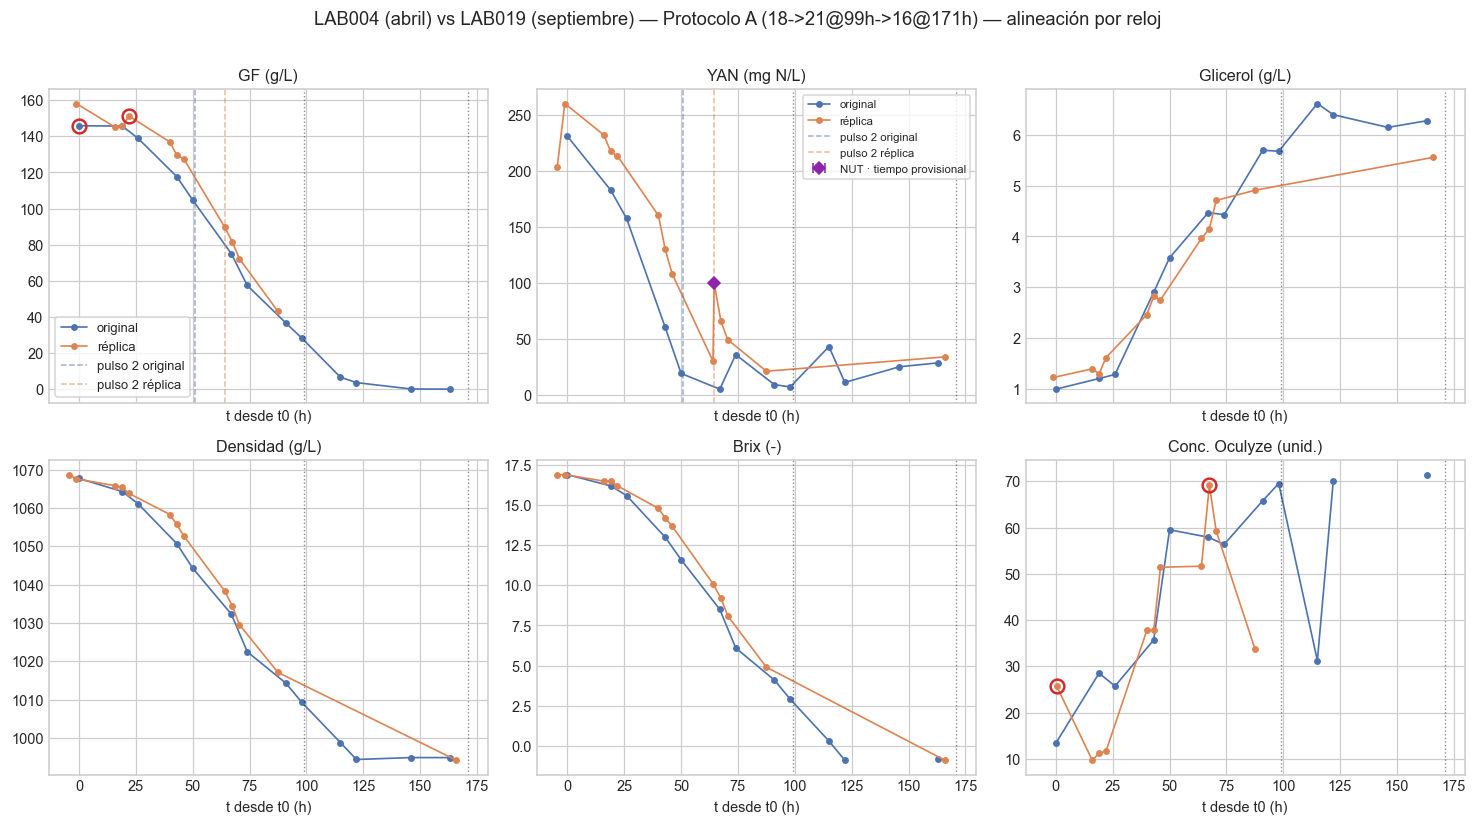

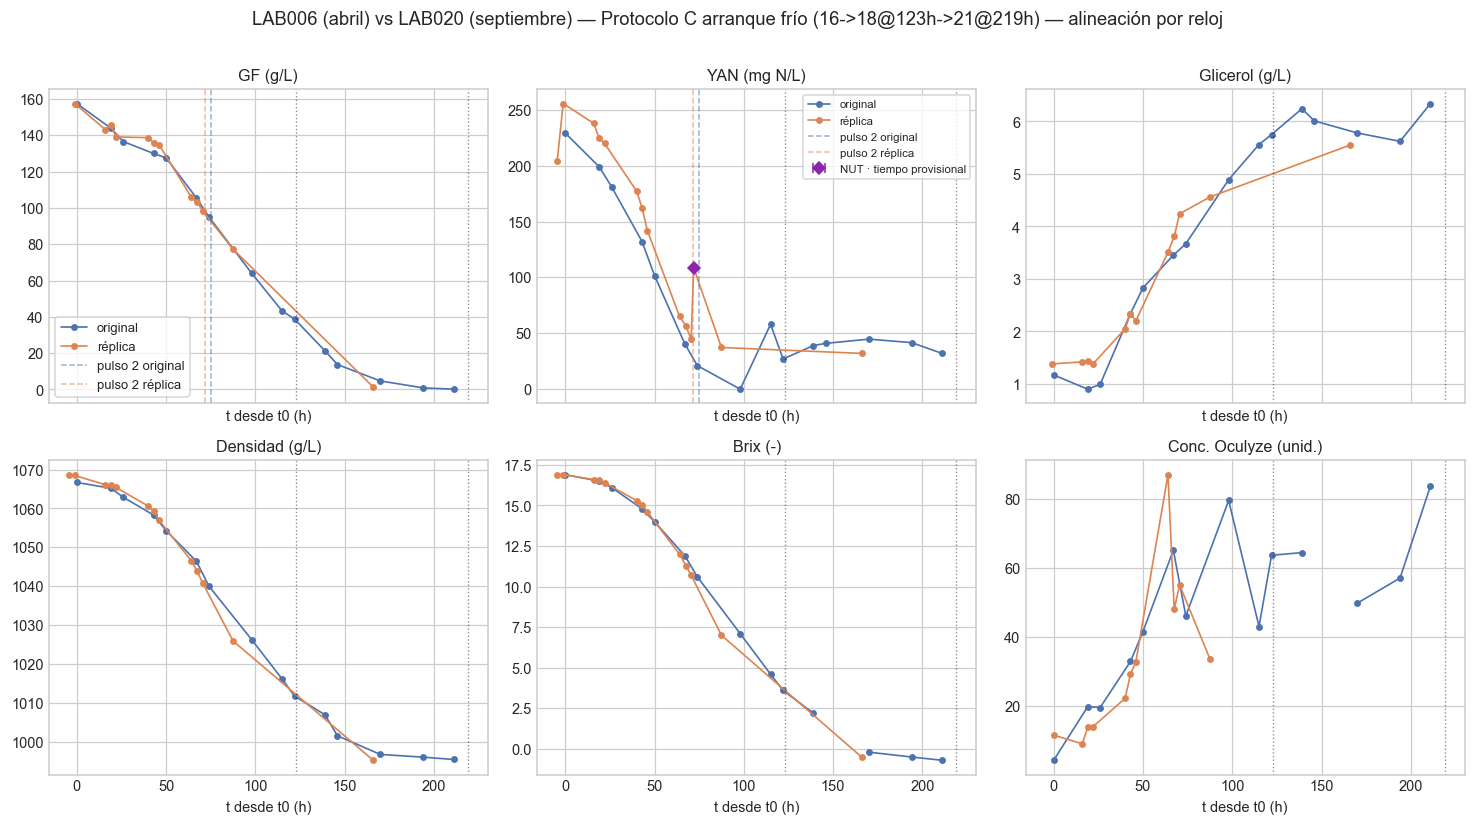

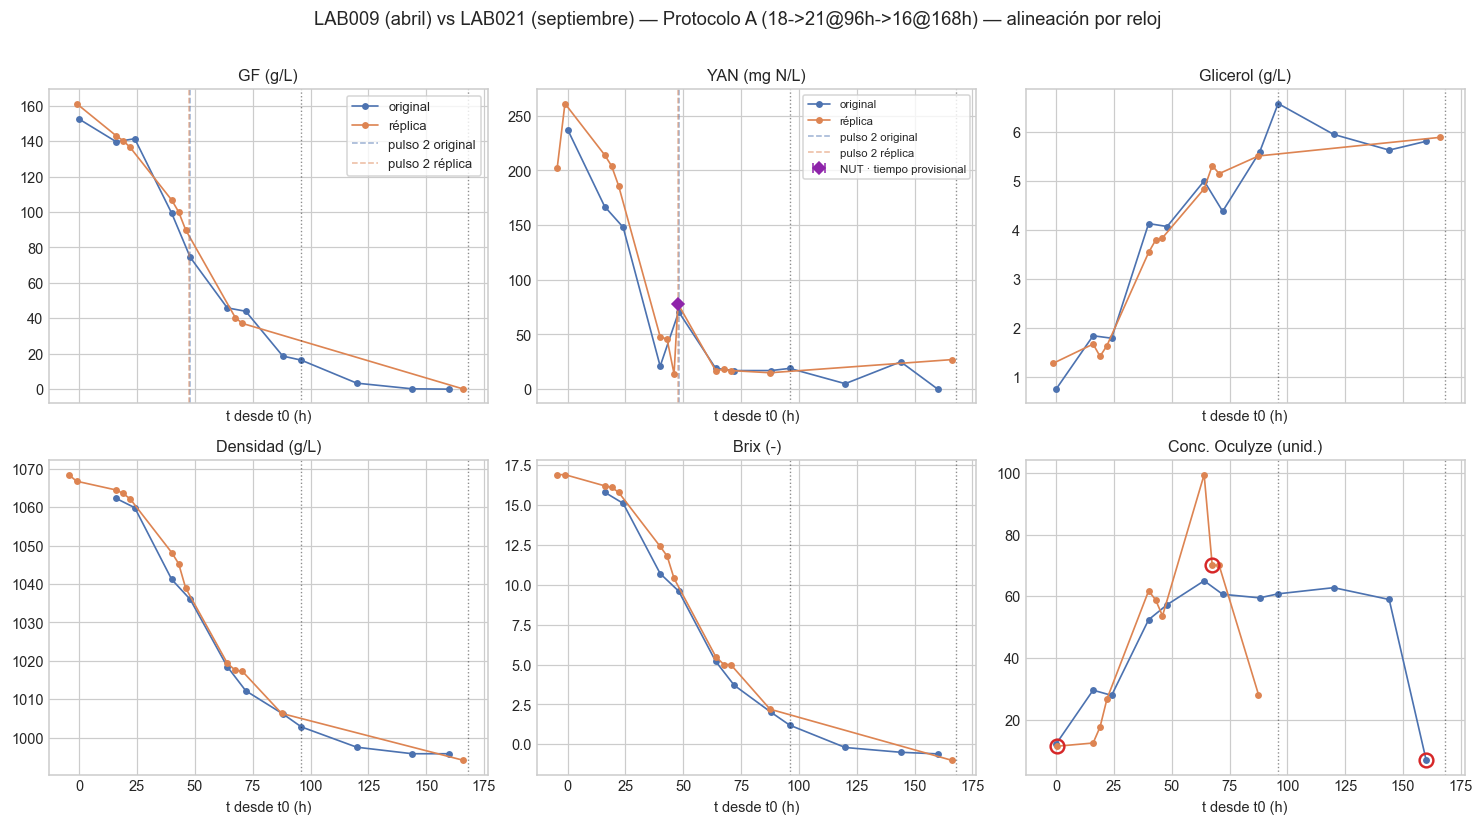

figura mostrada arriba (inline)


In [8]:
PANELS = [
    ("GF", "GF (g/L)"), ("YAN", "YAN (mg N/L)"), ("Gly", "Glicerol (g/L)"),
    ("density", "Densidad (g/L)"), ("Brix", "Brix (-)"), ("X", "Conc. Oculyze (unid.)"),
]

def serie(lab, panel):
    if lab in ORIG:
        df = ORIG[lab]
        col = {"YAN": "YAN", "X": "X_ocu", "Brix": "Brix_valid"}.get(panel, panel)
        return df.index.to_numpy(float), df[col].to_numpy(float)
    df = REPL[lab]
    if panel == "YAN":
        v = df["YAN_mgN"]
    elif panel == "X":
        xf = REPL_X[lab]
        return xf.index.to_numpy(float), xf["X_ocu"].to_numpy(float)
    else:
        v = df[panel]
    t, values = df["t_h"].to_numpy(float), v.to_numpy(float)
    valid = np.isfinite(t) & np.isfinite(values)
    return t[valid], values[valid]

for orig, repl, proto in PAIRS:
    fig, axes = plt.subplots(2, 3, figsize=(13.5, 7.6), sharex=True)
    for ax, (panel, title) in zip(axes.flat, PANELS):
        for lab, color, label in ((orig, COLOR_ORIG, "original"), (repl, COLOR_REPL, "réplica")):
            t, v = serie(lab, panel)
            ax.plot(t, v, color=color, marker="o", ms=3.5, lw=1.1, label=label)
            draw_nut(ax, lab, panel)
            for tm, vm in FLAG_MARKS.get((lab, panel), []):
                ax.plot(tm, vm, "o", mfc="none", mec=COLOR_FLAG, ms=9, mew=1.6)
        if panel in ("GF", "YAN"):
            ax.axvline(PULSE_ORIG_H[orig], color=COLOR_ORIG, ls="--", lw=1.0, alpha=0.55, label="pulso 2 original")
            ax.axvline(PULSE_REPL_H[repl], color=COLOR_REPL, ls="--", lw=1.0, alpha=0.55, label="pulso 2 réplica")
        for t_sp, _ in SP_EVENTS[orig]:
            ax.axvline(t_sp, color="k", ls=":", lw=0.9, alpha=0.45)
        ax.set_title(title)
        ax.set_xlabel("t desde t0 (h)")
    axes.flat[0].legend(loc="best", frameon=True, fontsize=8.5)
    axes.flat[1].legend(loc="best", frameon=True, fontsize=7.5)
    fig.suptitle(f"{orig} (abril) vs {repl} (septiembre) — {proto} — alineación por reloj", fontsize=12)
    fig.tight_layout(rect=(0, 0, 1, 0.97))
    display_inline_figure(fig)
    plt.close(fig)
print("figura mostrada arriba (inline)")

## Comparación conjunta por reloj

Los tres pares en una sola figura, con las mismas señales de la alineación por estado.
El eje horizontal es el tiempo transcurrido desde el t0 de cada lote; los círculos rojos indican flags de QA.

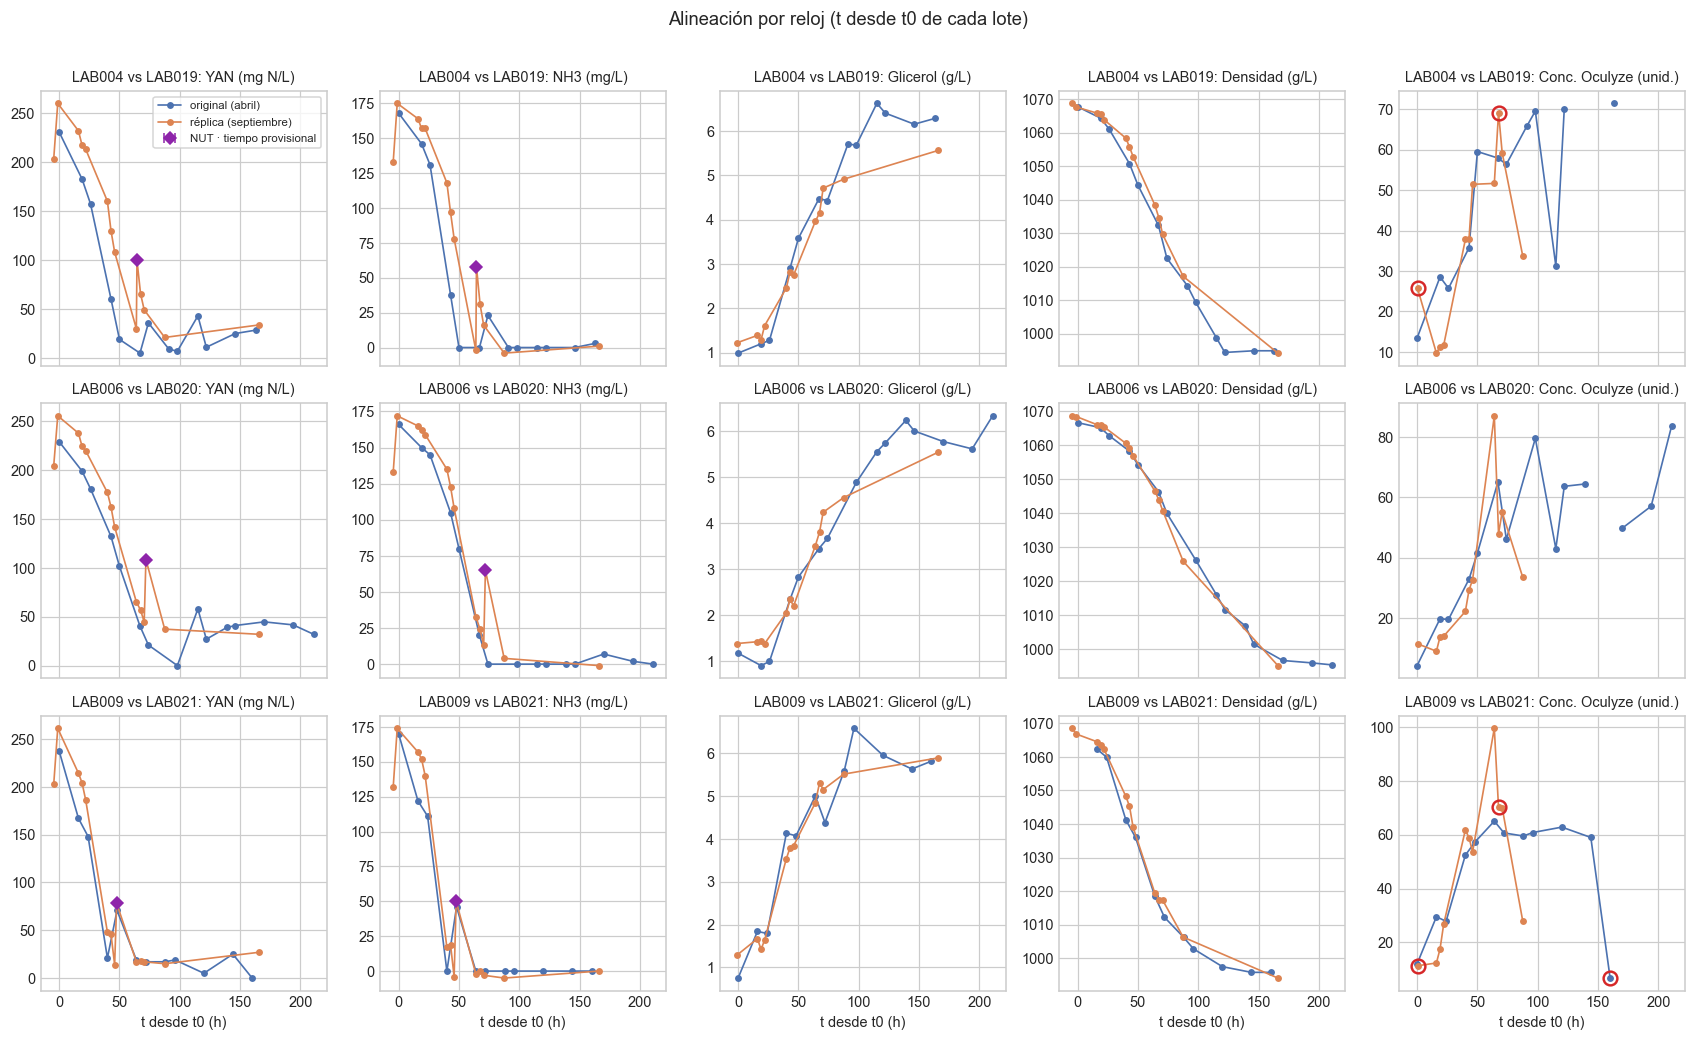

figura mostrada arriba (inline)


In [9]:
COMPARISON_PANELS = [("YAN", "YAN (mg N/L)"), ("NH3", "NH3 (mg/L)"), ("Gly", "Glicerol (g/L)"),
                     ("density", "Densidad (g/L)"), ("X", "Conc. Oculyze (unid.)")]

fig, axes = plt.subplots(len(PAIRS), len(COMPARISON_PANELS), figsize=(15.5, 3.2 * len(PAIRS)), sharex=True)
for row, (orig, repl, _proto) in enumerate(PAIRS):
    for ax, (panel, title) in zip(axes[row], COMPARISON_PANELS):
        for lab, color, label in ((orig, COLOR_ORIG, "original (abril)"), (repl, COLOR_REPL, "réplica (septiembre)")):
            t, v = serie(lab, panel)
            ax.plot(t, v, color=color, marker="o", ms=3.5, lw=1.1, label=label)
            draw_nut(ax, lab, panel)
            for tm, vm in FLAG_MARKS.get((lab, panel), []):
                ax.plot(tm, vm, "o", mfc="none", mec=COLOR_FLAG, ms=9, mew=1.6)
        ax.set_title(f"{orig} vs {repl}: {title}", fontsize=9.5)
        if row == len(PAIRS) - 1:
            ax.set_xlabel("t desde t0 (h)")
axes[0, 0].legend(loc="best", frameon=True, fontsize=7.5)
fig.suptitle("Alineación por reloj (t desde t0 de cada lote)", fontsize=12)
fig.tight_layout(rect=(0, 0, 1, 0.97))
display_inline_figure(fig)
plt.close(fig)
print("figura mostrada arriba (inline)")

## Curvas de CO2: réplica vs original (alineación por reloj)

Comparación de la señal de flujo de CO2 por par. Las réplicas provienen del backup global del logger (`backup_global_co2.csv`, canal filtrado); los originales se cargan con el loader histórico del repositorio (t0 del workbook, archivos partidos PT1/PT2, resample 10 min) y se reconvierten con la MISMA convención de las réplicas: factor documentado **0.0404 g L⁻¹ h⁻¹ por sccm**, cero del sensor por cuantil 10 % de [2.5, 12] h, mediana horaria, integración/ventana desde 2.5 h (fuera de la zona de agitación del arranque). Líneas punteadas: nutrición tardía de cada fermentación (azul original, naranja réplica).

Advertencia de comparabilidad conocida: los originales sufrieron fugas crecientes del gas antes del medidor (LAB004 ~57 % del CO2 estequiométrico perdido, LAB006 ~70 %, LAB009 ~88 %), de modo que sus curvas subestiman la emisión real — especialmente LAB009, cuya curva baja no es biología sino medición.

,original,replica,AUC_original_0_160h_g_L,AUC_replica_0_160h_g_L,pico_original_g_L_h,pico_replica_g_L_h,t_pico_original_h,t_pico_replica_h,ratio_AUC_replica_original
0,LAB004,LAB019,30.82,35.47,0.59,0.67,49.0,71.0,1.15
1,LAB006,LAB020,21.31,31.62,0.30,0.52,74.0,81.0,1.48
2,LAB009,LAB021,8.95,36.15,0.36,0.96,89.0,53.0,4.04


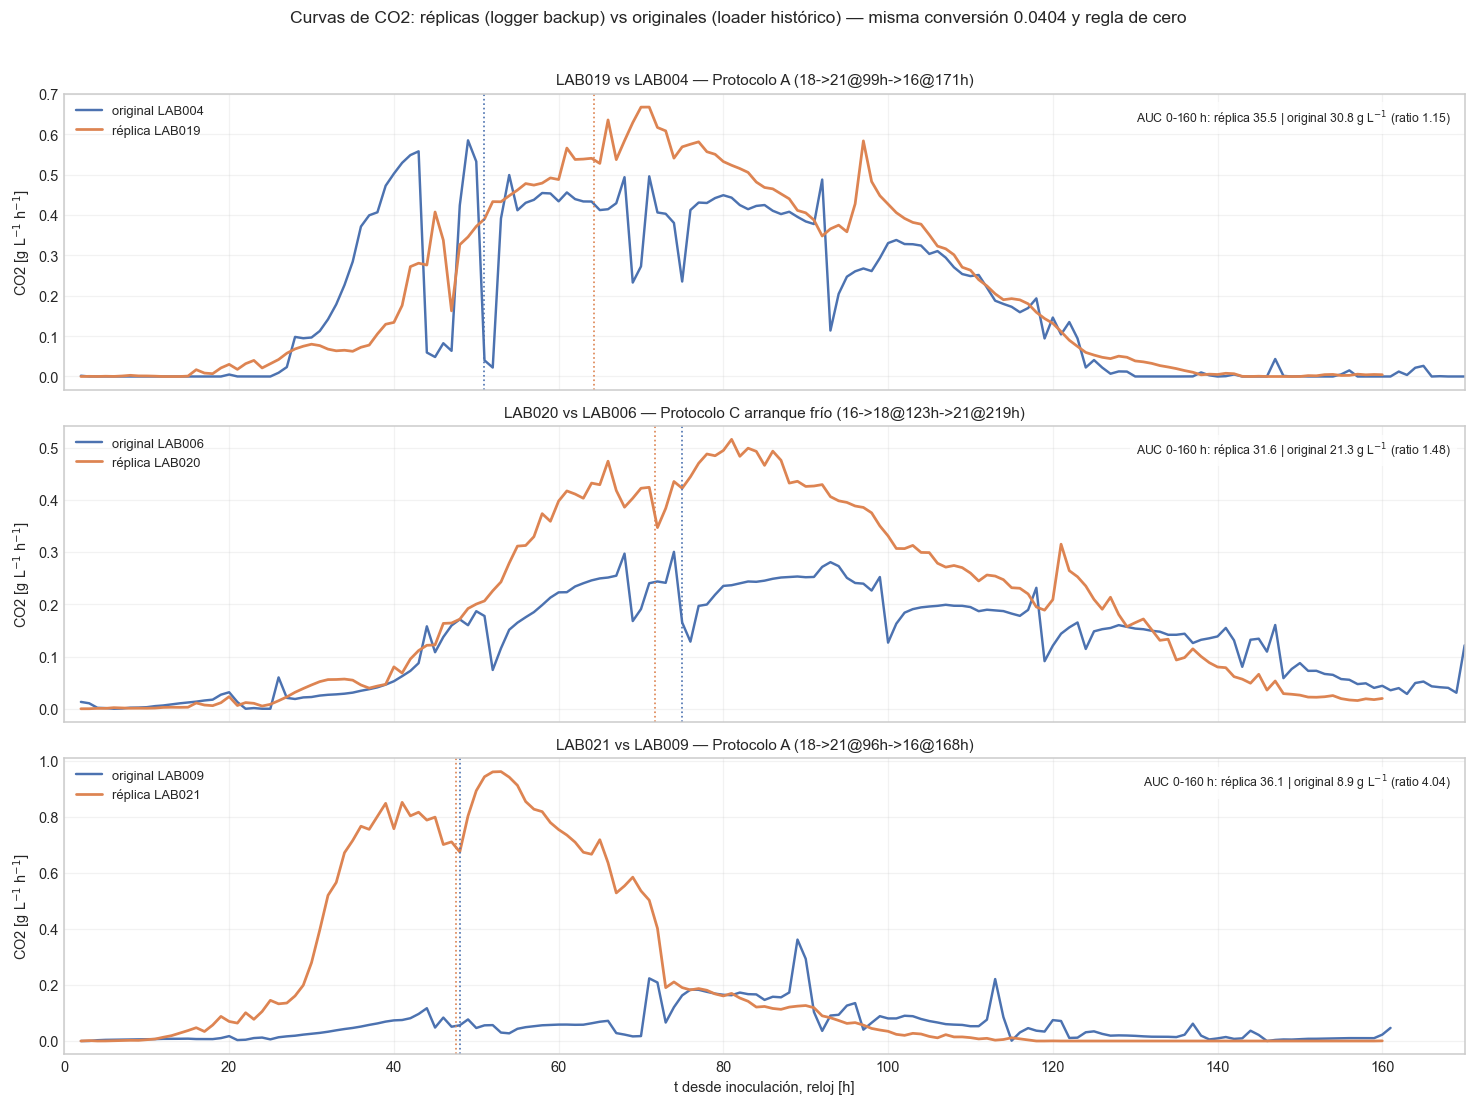

Convención CO2: inicio 2.5 h, cero p10 de [2.5, 12] h, mediana horaria, 0.0404 g/L/h por sccm.


In [10]:
import sys as _sys

for _p in (FM, FM / "laboratory_2026", FM / "pilot_2025"):
    if str(_p) not in _sys.path:
        _sys.path.insert(0, str(_p))
from laboratory_2026 import run_estimability_historical_by_medium as _hist

CO2_FACTOR_G_L_H_PER_SCCM = 0.0404391928807947  # conversión documentada (44.0095*60*0.74/(1000*24.16*2))
CO2_START_H, CO2_ZERO_END_H, CO2_XMAX = 2.5, 12.0, 170.0
FERM_REPL = {"LAB019": "F1", "LAB020": "F2", "LAB021": "F3"}


def _co2_hourly(t_h, flow_sccm):
    df = pd.DataFrame({"t_h": np.asarray(t_h, float), "flow": np.asarray(flow_sccm, float)}).dropna()
    df = df[df["t_h"].ge(CO2_START_H)]
    if df.empty:
        return pd.DataFrame(columns=["t_h", "rate"])
    window = df.loc[df["t_h"].le(CO2_ZERO_END_H), "flow"]
    zero = max(float(window.quantile(0.10)), 0.0) if len(window) else 0.0
    df["rate"] = (df["flow"] - zero).clip(lower=0.0) * CO2_FACTOR_G_L_H_PER_SCCM
    hourly = df.groupby(np.floor(df["t_h"]).astype(int))["rate"].median().reset_index()
    hourly.columns = ["t_h", "rate"]
    return hourly


def _co2_auc(hourly, t_max):
    d = hourly[hourly["t_h"].le(t_max)]
    if len(d) < 2:
        return float("nan")
    t, y = d["t_h"].to_numpy(float), d["rate"].to_numpy(float)
    return float(np.sum(0.5 * (y[1:] + y[:-1]) * np.diff(t)))


_co2_parts = []
for _chunk in pd.read_csv(
    REPLICA_DIR / "backup_global_co2.csv",
    usecols=["timestamp", "fermentador", "flow_filt_sccm"],
    chunksize=500_000, low_memory=False,
):
    _stamp = pd.to_datetime(_chunk["timestamp"], errors="coerce")
    _keep = _stamp.between(datetime(2026, 9, 21, 11, 0), datetime(2026, 9, 28, 15, 0))
    if _keep.any():
        _part = _chunk.loc[_keep].copy()
        _part["timestamp"] = _stamp.loc[_keep]
        _co2_parts.append(_part)
_co2_backup = pd.concat(_co2_parts, ignore_index=True)
_co2_backup["flow_filt_sccm"] = pd.to_numeric(_co2_backup["flow_filt_sccm"], errors="coerce")

_orig_meta = _hist.load_natural_batch_metadata([orig for orig, _, _ in PAIRS])

co2_curves = {}
co2_auc_rows = []
for orig, repl, _proto in PAIRS:
    fr = _co2_backup[_co2_backup["fermentador"].eq(FERM_REPL[repl])].dropna(subset=["flow_filt_sccm"]).copy()
    fr["t_h"] = (fr["timestamp"] - pd.Timestamp(T0_REPL[repl])).dt.total_seconds() / 3600.0
    repl_hourly = _co2_hourly(fr["t_h"], fr["flow_filt_sccm"])

    meta_row = _orig_meta[_orig_meta["batch"].eq(orig)].iloc[0]
    parts = [_hist.read_process_file(r)[0] for r in _hist.discover_process_files(orig) if r["kind"] == "co2"]
    sampled = _hist.resample_process_signal(
        pd.concat(parts, ignore_index=True), "co2", meta_row["t0"], 400.0, float(meta_row["reactor_volume_l"])
    )
    orig_hourly = _co2_hourly(sampled["t_h"], sampled["flow_filt_sccm"])
    co2_curves[(orig, repl)] = (orig_hourly, repl_hourly)
    co2_auc_rows.append({
        "original": orig, "replica": repl,
        "AUC_original_0_160h_g_L": _co2_auc(orig_hourly, 160.0),
        "AUC_replica_0_160h_g_L": _co2_auc(repl_hourly, 160.0),
        "pico_original_g_L_h": float(orig_hourly["rate"].max()) if len(orig_hourly) else float("nan"),
        "pico_replica_g_L_h": float(repl_hourly["rate"].max()) if len(repl_hourly) else float("nan"),
        "t_pico_original_h": float(orig_hourly.loc[orig_hourly["rate"].idxmax(), "t_h"]) if len(orig_hourly) else float("nan"),
        "t_pico_replica_h": float(repl_hourly.loc[repl_hourly["rate"].idxmax(), "t_h"]) if len(repl_hourly) else float("nan"),
    })

co2_auc_table = pd.DataFrame(co2_auc_rows)
co2_auc_table["ratio_AUC_replica_original"] = co2_auc_table["AUC_replica_0_160h_g_L"] / co2_auc_table["AUC_original_0_160h_g_L"]
display(co2_auc_table.round(2))

fig, axes = plt.subplots(len(PAIRS), 1, figsize=(13.5, 3.4 * len(PAIRS)), sharex=True)
for ax, (orig, repl, proto), row in zip(axes, PAIRS, co2_auc_rows):
    orig_hourly, repl_hourly = co2_curves[(orig, repl)]
    ax.plot(orig_hourly["t_h"], orig_hourly["rate"], color=COLOR_ORIG, lw=1.6, label=f"original {orig}")
    ax.plot(repl_hourly["t_h"], repl_hourly["rate"], color=COLOR_REPL, lw=1.8, label=f"réplica {repl}")
    ax.axvline(PULSE_ORIG_H[orig], color=COLOR_ORIG, ls=":", lw=1.1)
    ax.axvline(PULSE_REPL_H[repl], color=COLOR_REPL, ls=":", lw=1.1)
    auc_o = co2_auc_table.loc[co2_auc_table["replica"].eq(repl), "AUC_original_0_160h_g_L"].iloc[0]
    auc_r = co2_auc_table.loc[co2_auc_table["replica"].eq(repl), "AUC_replica_0_160h_g_L"].iloc[0]
    ax.text(
        0.99, 0.95,
        f"AUC 0-160 h: réplica {auc_r:.1f} | original {auc_o:.1f} g L$^{{-1}}$ (ratio {auc_r / max(auc_o, 1e-9):.2f})",
        transform=ax.transAxes, ha="right", va="top", fontsize=8,
        bbox=dict(facecolor="white", alpha=0.75, edgecolor="none"),
    )
    ax.set_title(f"{repl} vs {orig} — {proto}", fontsize=10)
    ax.set_ylabel("CO2 [g L$^{{-1}}$ h$^{{-1}}$]")
    ax.legend(fontsize=8.5, loc="upper left")
    ax.grid(alpha=0.25)
axes[-1].set_xlabel("t desde inoculación, reloj [h]")
axes[-1].set_xlim(0.0, CO2_XMAX)
fig.suptitle("Curvas de CO2: réplicas (logger backup) vs originales (loader histórico) — misma conversión 0.0404 y regla de cero")
fig.tight_layout(rect=(0, 0, 1, 0.965))
display_inline_figure(fig)
plt.close(fig)
print("Convención CO2: inicio 2.5 h, cero p10 de [2.5, 12] h, mediana horaria, 0.0404 g/L/h por sccm.")

## Alineación por estado (azúcar consumida)

Mismas señales contra C = GF0 − GF de cada lote: elimina el corrimiento temporal y compara la
*forma* (p. ej., la meseta GF≈40–45 de LAB021 contra la de LAB009 queda visible a igual progreso).
Nota: el GF0 de LAB004 está marcado como inconsistente, por lo que su C arrastra ese offset.

Para NUT, sin azúcar medida, el diamante usa GF interpolada sólo para esta alineación visual. No se crea una medición de azúcar ni se usa en los hitos.


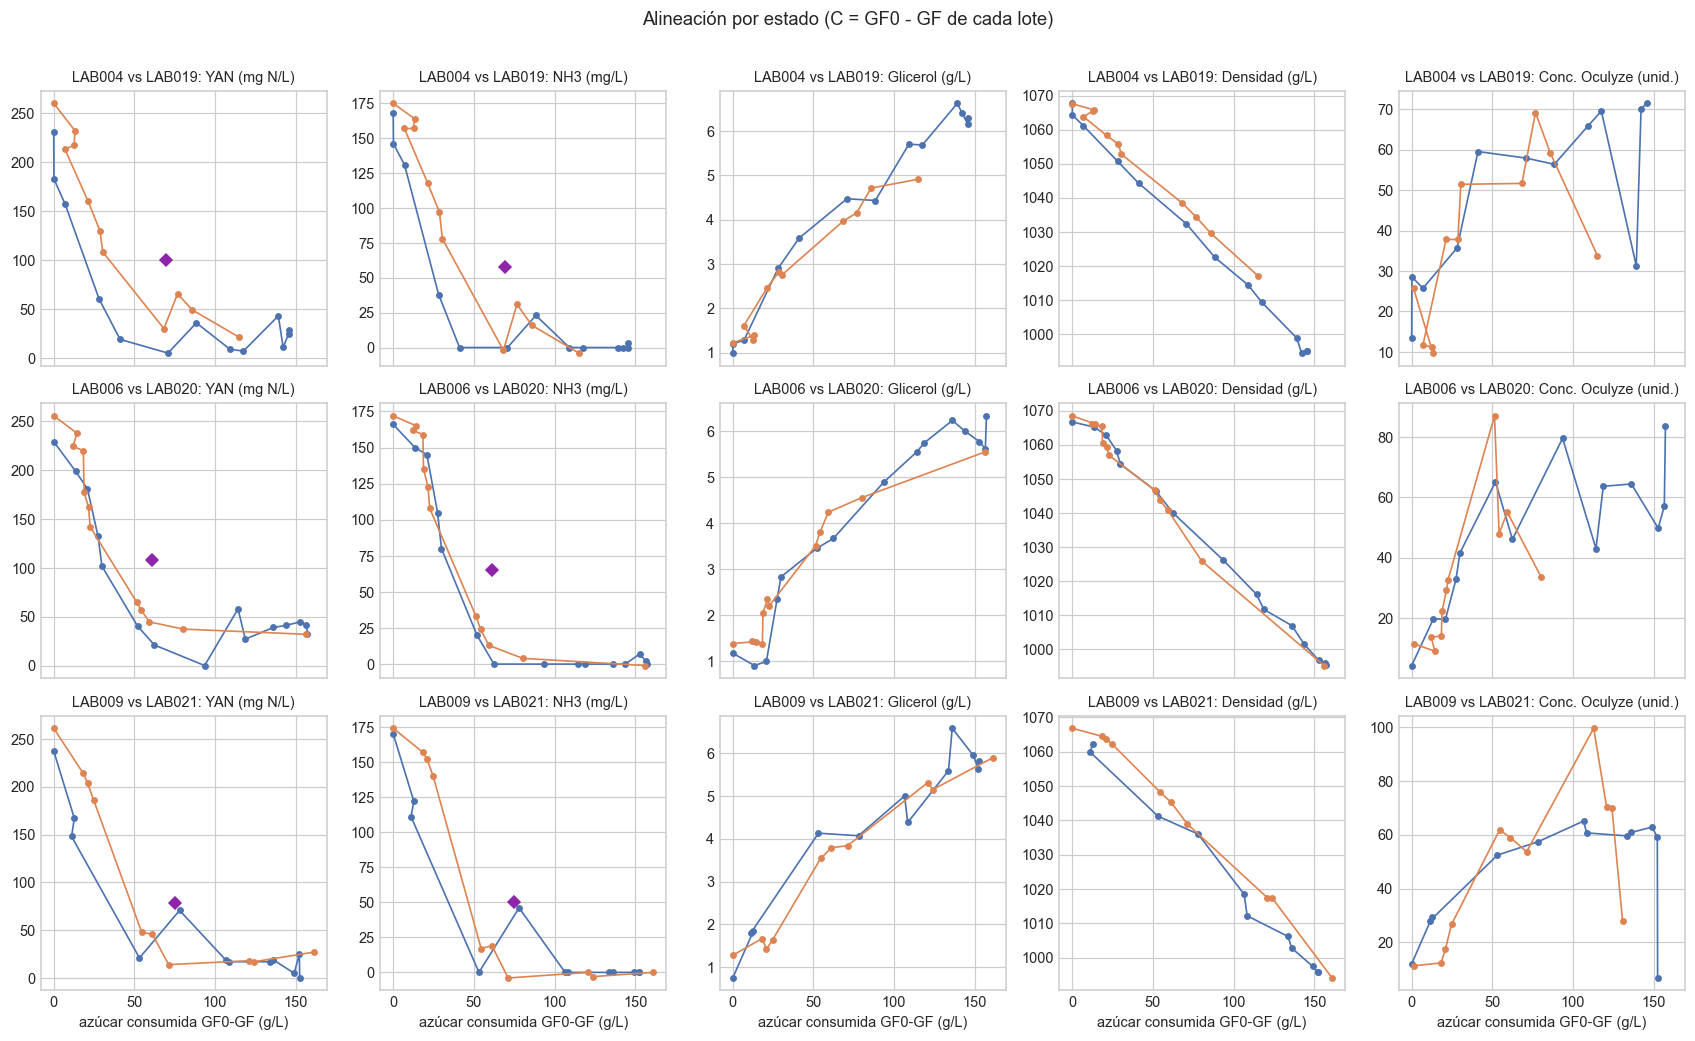

figura mostrada arriba (inline)


In [11]:
def consumed(lab):
    df = ORIG[lab] if lab in ORIG else REPL[lab]
    gf = df["GF"].to_numpy(float)
    gf0 = np.nanmax(gf[:1]) if lab in ORIG else REPL[lab]["GF"].dropna().iloc[0]
    t = df.index.to_numpy(float) if lab in ORIG else df["t_h"].to_numpy(float)
    return t, gf0 - gf, gf0

fig, axes = plt.subplots(len(PAIRS), len(COMPARISON_PANELS), figsize=(15.5, 3.2 * len(PAIRS)), sharex=True)
for row, (orig, repl, _proto) in enumerate(PAIRS):
    for ax, (panel, title) in zip(axes[row], COMPARISON_PANELS):
        for lab, color in ((orig, COLOR_ORIG), (repl, COLOR_REPL)):
            if panel == "X" and lab in REPL:
                xf = REPL_X[lab]
                df = REPL[lab]
                gf = df["GF"].to_numpy(float); t_gf = df["t_h"].to_numpy(float)
                ok = np.isfinite(gf)
                gf0 = np.nanmax(gf[ok][:1])
                t_x = xf.index.to_numpy(float)
                c_x = np.interp(t_x, t_gf[ok], gf0 - gf[ok])
                ax.plot(c_x, xf["X_ocu"].to_numpy(float), color=color, marker="o", ms=3.5, lw=1.1)
                continue
            t, c, gf0 = consumed(lab)
            df = ORIG[lab] if lab in ORIG else REPL[lab]
            if panel == "YAN":
                v = df["YAN"].to_numpy(float) if lab in ORIG else df["YAN_mgN"].to_numpy(float)
            elif panel == "NH3":
                v = df["NH3"].to_numpy(float)
            else:
                col = "X_ocu" if panel == "X" else panel
                v = df[col].to_numpy(float)
            valid = np.isfinite(c) & np.isfinite(v)
            ax.plot(c[valid], v[valid], color=color, marker="o", ms=3.5, lw=1.1)
            draw_nut(ax, lab, panel, state_axis=True)
        ax.set_title(f"{orig} vs {repl}: {title}", fontsize=9.5)
        if row == len(PAIRS) - 1:
            ax.set_xlabel("azúcar consumida GF0-GF (g/L)")
fig.suptitle("Alineación por estado (C = GF0 - GF de cada lote)", fontsize=12)
fig.tight_layout(rect=(0, 0, 1, 0.97))
display_inline_figure(fig)
plt.close(fig)
print("figura mostrada arriba (inline)")

## Hitos: original vs réplica (barras agrupadas con Δ)

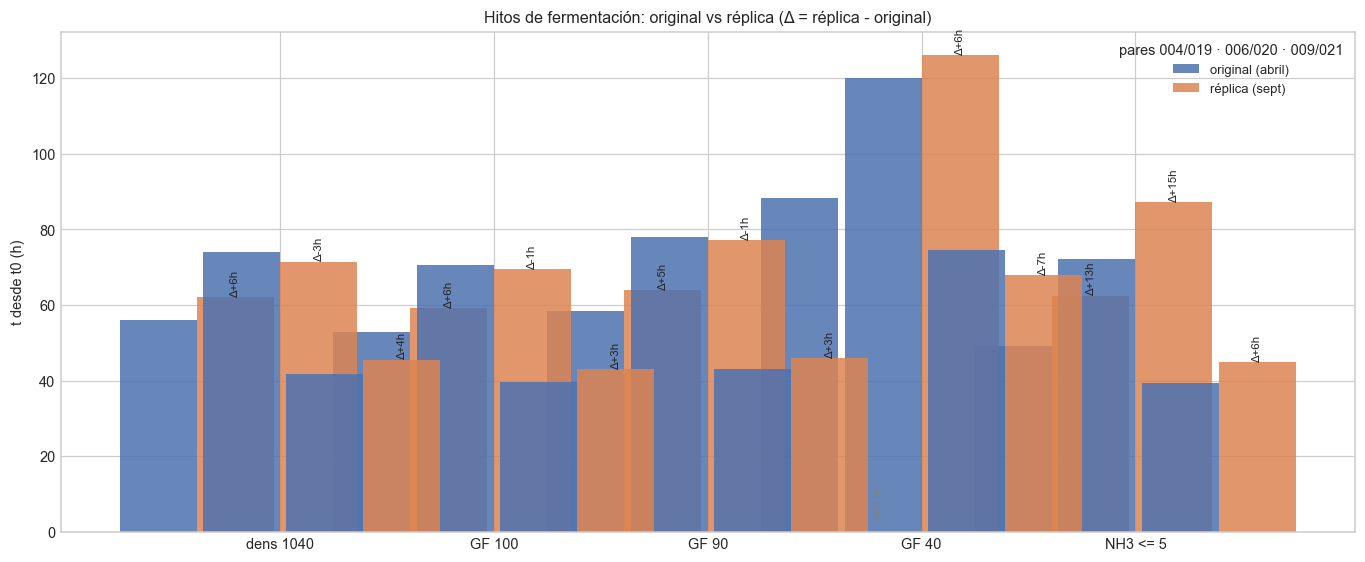

figura mostrada arriba (inline)


In [12]:
fig, ax = plt.subplots(figsize=(12.5, 5.2))
xg = np.arange(len(MILESTONE_DEFS)); width = 0.36
handles = []
for k, (orig, repl, _p) in enumerate(PAIRS):
    off = (k - 1) * (width + 0.03)
    vals_o = [milestones_df.loc[orig, c] for c, _s in MILESTONE_DEFS]
    vals_r = [milestones_df.loc[repl, c] for c, _s in MILESTONE_DEFS]
    b1 = ax.bar(xg + off - width / 2, vals_o, width, color=COLOR_ORIG, alpha=0.85)
    b2 = ax.bar(xg + off + width / 2, vals_r, width, color=COLOR_REPL, alpha=0.85)
    if k == 0:
        handles = [b1, b2]
    for xi, (vo, vr) in enumerate(zip(vals_o, vals_r)):
        if np.isfinite(vr):
            ax.annotate(f"Δ{vr - vo:+.0f}h", (xg[xi] + off + width / 2, vr), fontsize=7.5,
                        ha="center", va="bottom", rotation=90)
        else:
            ax.annotate("aún no", (xg[xi] + off + width / 2, 4), fontsize=7, ha="center",
                        rotation=90, color="gray")
ax.set_xticks(xg)
ax.set_xticklabels([s for _c, s in MILESTONE_DEFS])
ax.set_ylabel("t desde t0 (h)")
ax.legend(handles, ["original (abril)", "réplica (sept)"], title="pares 004/019 · 006/020 · 009/021", fontsize=8.5)
ax.set_title("Hitos de fermentación: original vs réplica (Δ = réplica - original)")
fig.tight_layout()
display_inline_figure(fig)
plt.close(fig)
print("figura mostrada arriba (inline)")

## Paneles secundarios (donde hay datos): pirúvico, acético, acetaldehído, etanol (réplicas nuevas: columna
`Etanol` del Excel, % v/v; originales: `ETANOL` del workbook, misma unidad) + viabilidad de réplicas

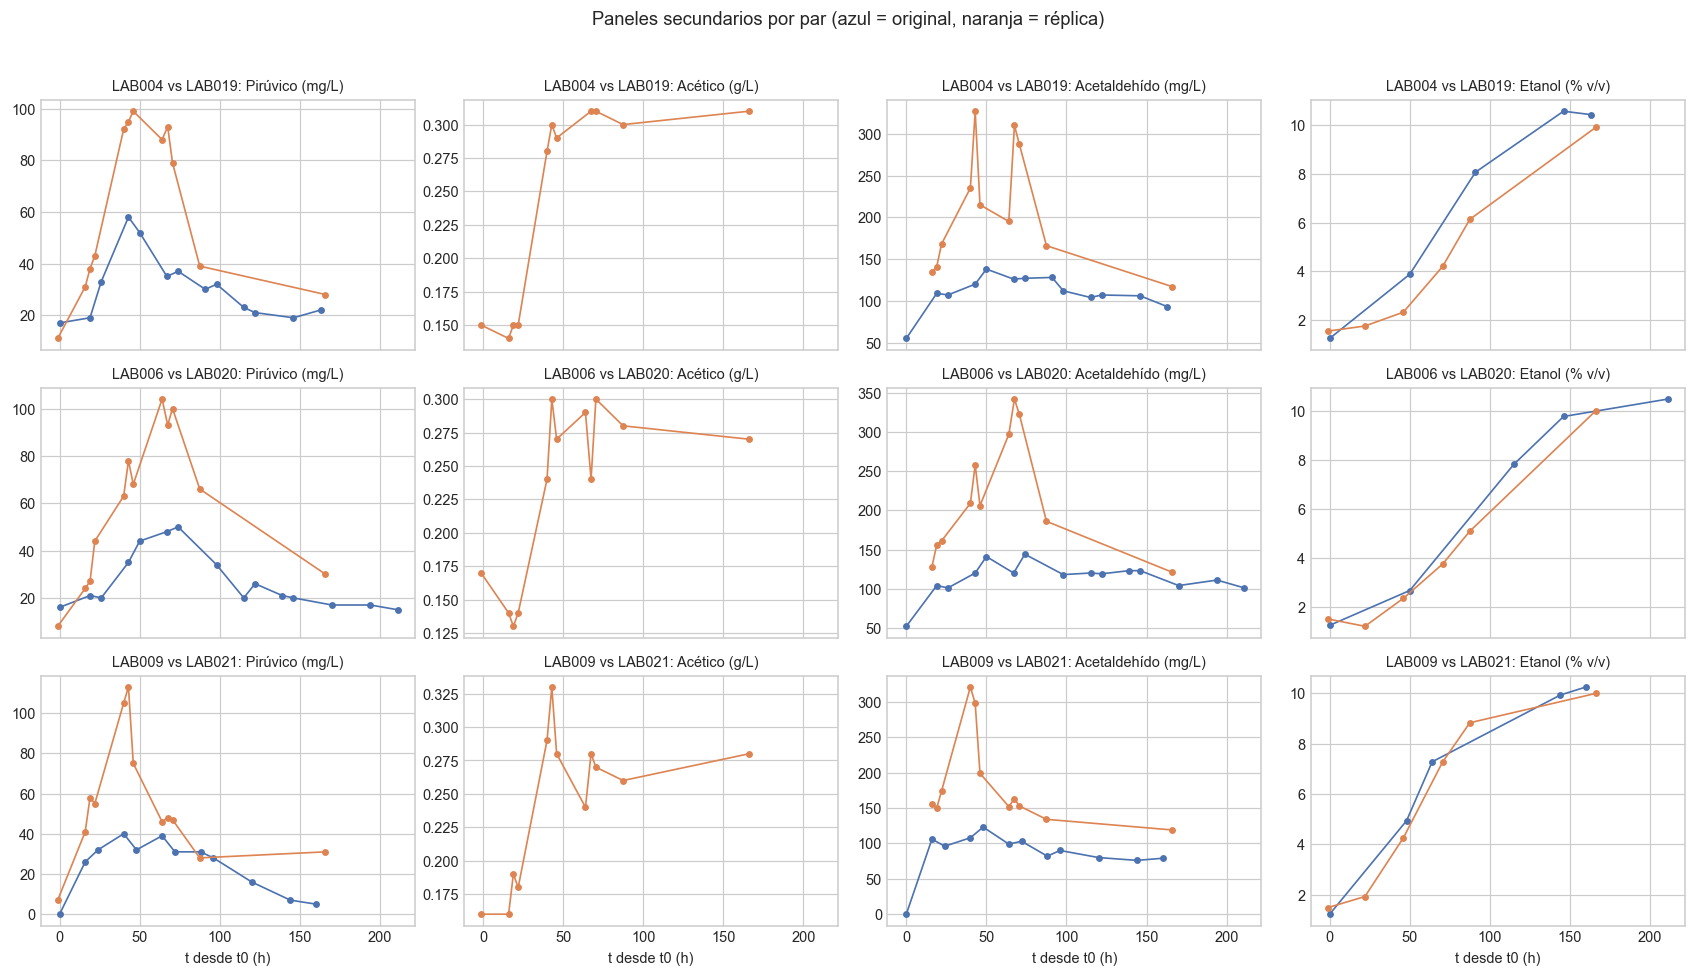

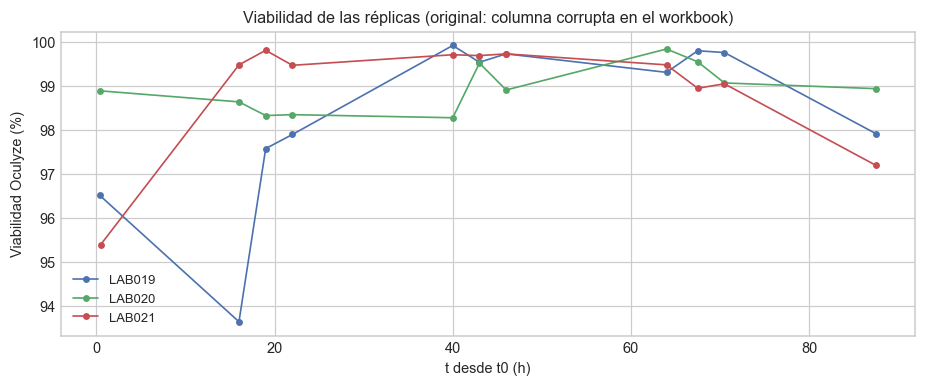

figura mostrada arriba (inline)


In [13]:
fig, axes = plt.subplots(len(PAIRS), 4, figsize=(15.5, 3.0 * len(PAIRS)), sharex=True)
SEC = [("piruvico", "Pirúvico (mg/L)"), ("acetic", "Acético (g/L)"),
       ("acetaldehido", "Acetaldehído (mg/L)"), ("etanol", "Etanol (% v/v)")]
for row, (orig, repl, _p) in enumerate(PAIRS):
    for ax, (panel, title) in zip(axes[row], SEC):
        for lab, color in ((orig, COLOR_ORIG), (repl, COLOR_REPL)):
            df = ORIG[lab] if lab in ORIG else REPL[lab]
            t = df.index.to_numpy(float) if lab in ORIG else df["t_h"].to_numpy(float)
            if panel not in df.columns:
                continue
            v = df[panel].to_numpy(float)
            if not np.isfinite(v).any():
                continue
            ok = np.isfinite(v)  # une los puntos medidos aunque haya muestras sin medir entre medio
            ax.plot(t[ok], v[ok], color=color, marker="o", ms=3.5, lw=1.1)
        ax.set_title(f"{orig} vs {repl}: {title}", fontsize=9.5)
        if row == len(PAIRS) - 1:
            ax.set_xlabel("t desde t0 (h)")
fig.suptitle("Paneles secundarios por par (azul = original, naranja = réplica)", fontsize=12)
fig.tight_layout(rect=(0, 0, 1, 0.96))
display_inline_figure(fig)
plt.close(fig)

fig2, axv = plt.subplots(figsize=(8.5, 3.6))
for lab, color in zip(("LAB019", "LAB020", "LAB021"), ("#4c72b0", "#55a868", "#c44e52")):
    xf = REPL_X[lab]
    axv.plot(xf.index, xf["viab"], color=color, marker="o", ms=3.5, lw=1.1, label=lab)
axv.set_xlabel("t desde t0 (h)")
axv.set_ylabel("Viabilidad Oculyze (%)")
axv.set_title("Viabilidad de las réplicas (original: columna corrupta en el workbook)")
axv.legend(fontsize=8.5)
fig2.tight_layout()
display_inline_figure(fig2)
plt.close(fig2)
print("figura mostrada arriba (inline)")

## Dispersión por par (grupo A vs C) y auditoría de entradas

In [14]:
disp_rows = []
for orig, repl, _proto in PAIRS:
    grupo = "C (arranque frío)" if orig == "LAB006" else "A"
    for col, short in MILESTONE_DEFS:
        vo, vr = milestones_df.loc[orig, col], milestones_df.loc[repl, col]
        if np.isfinite(vo) and np.isfinite(vr):
            disp_rows.append({"par": f"{orig}->{repl}", "grupo": grupo, "hito": short,
                              "t_original_h": vo, "t_replica_h": vr, "delta_h": vr - vo})
disp_df = pd.DataFrame(disp_rows)
summary = disp_df.groupby("grupo")["delta_h"].agg(["count", "mean", "std", lambda s: s.abs().mean()])
summary.columns = ["n", "media Δ (h)", "std Δ (h)", "media |Δ| (h)"]
disp_df.round(2).to_csv(RESULTS_DIR / "dispersion_por_par.csv", index=False, encoding="utf-8-sig")
summary.round(2).to_csv(RESULTS_DIR / "dispersion_resumen.csv", encoding="utf-8-sig")
display(summary.round(2))
display(disp_df.round(2))

audit_rows = []
for lab in ("LAB004", "LAB006", "LAB009", "LAB019", "LAB020", "LAB021"):
    if lab in ORIG:
        df = ORIG[lab]
        audit_rows.append({"lote": lab, "campaña": "abril (original)",
                           "n_GF": int(df["GF"].notna().sum()), "n_YAN": int(df["YAN"].notna().sum()),
                           "n_densidad": int(df["density"].notna().sum()),
                           "n_Brix": int(df["Brix_valid"].notna().sum()),
                           "n_X_ocu": int(df["X_ocu"].notna().sum()),
                           "n_etanol": int(df["etanol"].notna().sum()),
                           "t_max_h": float(df.index.max())})
    else:
        df = REPL[lab]
        audit_rows.append({"lote": lab, "campaña": "sept (réplica)",
                           "n_GF": int(df["GF"].notna().sum()), "n_YAN": int(df["YAN_mgN"].notna().sum()),
                           "n_densidad": int(df["density"].notna().sum()),
                           "n_Brix": int(df["Brix"].notna().sum()),
                           "n_X_ocu": int(REPL_X[lab]["X_ocu"].notna().sum()),
                           "n_etanol": int(df["etanol"].notna().sum()),
                           "t_max_h": float(df["t_h"].max())})
audit_df = pd.DataFrame(audit_rows)
audit_df.to_csv(RESULTS_DIR / "input_audit.csv", index=False, encoding="utf-8-sig")
display(audit_df)

,n,media Δ (h),std Δ (h),media |Δ| (h)
grupo,,,,
A,9,4.45,5.19,5.93
C (arranque frío),5,3.30,7.34,5.11


,par,grupo,hito,t_original_h,t_replica_h,delta_h
0,LAB004->LAB019,A,dens 1040,56.09,62.00,5.91
1,LAB004->LAB019,A,GF 100,52.71,59.18,6.47
2,LAB004->LAB019,A,GF 90,58.43,63.93,5.50
3,LAB004->LAB019,A,NH3 <= 5,49.08,62.42,13.35
4,LAB006->LAB020,C (arranque frío),dens 1040,74.00,71.41,-2.59
5,LAB006->LAB020,C (arranque frío),GF 100,70.67,69.44,-1.22
6,LAB006->LAB020,C (arranque frío),GF 90,77.86,77.16,-0.70
7,LAB006->LAB020,C (arranque frío),GF 40,119.99,126.03,6.03
8,LAB006->LAB020,C (arranque frío),NH3 <= 5,72.25,87.24,14.99
9,LAB009->LAB021,A,dens 1040,41.85,45.52,3.68


,lote,campaña,n_GF,n_YAN,n_densidad,n_Brix,n_X_ocu,n_etanol,t_max_h
0,LAB004,abril (original),13,13,13,12,12,5,163.0
1,LAB006,abril (original),15,15,15,14,14,5,211.0
2,LAB009,abril (original),12,12,11,11,12,5,160.0
3,LAB019,sept (réplica),11,14,13,13,11,6,166.0
4,LAB020,sept (réplica),12,14,13,13,11,6,166.0
5,LAB021,sept (réplica),10,14,13,13,11,6,166.0


## Verificación de salidas

In [15]:
csv_expected = [
    "nut_sample_audit.csv", "replica_measurements_with_NUT.csv", "qa_flags.csv", "milestones.csv", "dispersion_por_par.csv", "dispersion_resumen.csv", "input_audit.csv",
]
missing = [name for name in csv_expected if not (RESULTS_DIR / name).exists()]
assert not missing, missing
print("OK:", len(csv_expected), "CSV en", RESULTS_DIR.relative_to(FM), "| figuras solo inline en este notebook (sin PNG en results)")

OK: 7 CSV en laboratory_2026\results\lab019_021_replica_vs_originals_data_comparison | figuras solo inline en este notebook (sin PNG en results)


## Notas de re-ejecución

- Re-ejecutar cuando llegue la muestra 16 (lunes 28/09 08:30): los hitos "aún no" (GF40 de LAB019/020)
  y la cola de LAB021 se completan solos.
- El etanol del Alcolyzer llegó a la columna `Etanol` del Excel offline y este notebook ya lo grafica
  (% v/v, misma unidad que `ETANOL` del workbook); el holdout cinético lo puntúa convertido a g/L (×7.8924).
- El log de temperatura del biorreactor sigue pendiente para notebooks posteriores (capa CO2).